# Developing Classification Methods for Target Role and Current Role
Classifying the "target role" and "current role" we parsed from relevant post titles.

In [2]:
import pandas as pd

## Loading Data
Loading all the roles associated with the sample data (target role + current role).

In [3]:
roles = pd.read_csv("data/intermediate/roles.csv")

In [4]:
roles.shape

(17021, 1)

In [5]:
unique_roles = roles.drop_duplicates()

In [6]:
unique_roles.shape

(7784, 1)

## Defining Taxonomy for Standardizing Job Roles
Using the SOC established taxonomy along with 6 amended groups for unrepresented types found in Reddit data.

In [7]:
# loads official soc taxonomy
soc_taxonomy = pd.read_excel("data/reference/soc_structure_2018.xlsx", skiprows=7)

In [8]:
# cleans up column names
soc_taxonomy.columns = [
    "Major Group",
    "Minor Group",
    "Broad Group",
    "Detailed Occupation",
    "Name"
]

In [9]:
# investigating counts before amending
soc_taxonomy.info()

<class 'pandas.DataFrame'>
RangeIndex: 1447 entries, 0 to 1446
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Major Group          23 non-null     str  
 1   Minor Group          98 non-null     str  
 2   Broad Group          459 non-null    str  
 3   Detailed Occupation  867 non-null    str  
 4   Name                 1447 non-null   str  
dtypes: str(5)
memory usage: 116.9 KB


In [10]:
# adds specific categories to SOC which don't exist yet
import numpy as np

extra_rows = pd.DataFrame(
    [
        {
            "Major Group": "99-0000",
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Non-Occupational and Transition Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": "99-1000",
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Unemployment and Labor Market Transition Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-1010",
            "Detailed Occupation": np.nan,
            "Name": "Unemployed and Involuntarily Displaced Workers",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-1011",
            "Name": (
                "Unemployed (General), Out of Work, Not Working, Without a Job"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-1012",
            "Name": (
                "Laid Off, Recently Laid Off, Downsized, Job Cut, Displaced"
                " Worker"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-1020",
            "Detailed Occupation": np.nan,
            "Name": "Active Job Seekers and Career Transitioners",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-1021",
            "Name": (
                "Looking for Work, Seeking Employment, Job Seeker, Job Hunting,"
                " Open to Work"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-1022",
            "Name": (
                "Career Break, Sabbatical, Serving Notice, Career Transition,"
                " Career Changer"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": "99-2000",
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Academic and Educational In-Training Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-2010",
            "Detailed Occupation": np.nan,
            "Name": "Enrolled Students and Interns",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-2011",
            "Name": (
                "Enrolled Student, Undergrad, College Student, University"
                " Student, Master's Student, PhD Candidate"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-2012",
            "Name": "Intern, Internship, Co-op, Student Intern, Summer Intern",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-2020",
            "Detailed Occupation": np.nan,
            "Name": "Recent Graduates and Entry-Level Entrants",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-2021",
            "Name": (
                "Recent Graduate, New Grad, Fresh Graduate, College Grad,"
                " Newly Graduated, Fresher"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": "99-3000",
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Independent, Freelance, and Entrepreneurial Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-3010",
            "Detailed Occupation": np.nan,
            "Name": "Self-Employed, Freelancers, and Business Founders",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-3011",
            "Name": (
                "Freelancer, Freelance, Independent Contractor, Contract Worker"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-3012",
            "Name": (
                "Self Employed, Founder, Co-Founder, Business Owner,"
                " Entrepreneur"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": "99-4000",
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Community Care, Volunteer, and Post-Career Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-4010",
            "Detailed Occupation": np.nan,
            "Name": "Family Caregivers and Community Volunteers",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-4011",
            "Name": (
                "Caregiver, Caretaker, Stay at Home Parent, Stay at Home Mom,"
                " Homemaker"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-4012",
            "Name": (
                "Volunteer, Volunteering, Unpaid Volunteer, Community Service"
            ),
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-4020",
            "Detailed Occupation": np.nan,
            "Name": "Retired and Semi-Retired Individuals",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-4021",
            "Name": "Retired, Semi-Retired, Post-Retirement",
        },
        {
            "Major Group": np.nan,
            "Minor Group": "99-5000",
            "Broad Group": np.nan,
            "Detailed Occupation": np.nan,
            "Name": "Exploratory and Unspecified Statuses",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": "99-5010",
            "Detailed Occupation": np.nan,
            "Name": "Undecided and General Career Explorers",
        },
        {
            "Major Group": np.nan,
            "Minor Group": np.nan,
            "Broad Group": np.nan,
            "Detailed Occupation": "99-5011",
            "Name": (
                "Anything, Undecided, General, Whatever, Any Job, Whatever I"
                " Can Get, Open to Anything"
            ),
        },
    ]
)

soc_taxonomy = pd.concat([soc_taxonomy, extra_rows], ignore_index=True)

In [11]:
# investigating numbers after amending
soc_taxonomy.info()

<class 'pandas.DataFrame'>
RangeIndex: 1474 entries, 0 to 1473
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Major Group          24 non-null     str  
 1   Minor Group          103 non-null    str  
 2   Broad Group          467 non-null    str  
 3   Detailed Occupation  880 non-null    str  
 4   Name                 1474 non-null   str  
dtypes: str(5)
memory usage: 119.6 KB


In [29]:
soc_taxonomy.to_csv("data/reference/amended_soc_structure.csv", index=False)

### Building LLM Classifier

In [12]:
# initialize llm
from typing import Optional, TypedDict
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="gemma4:e4b-mlx",
    temperature=0.0,
    format="json"
)

In [13]:
# preprocess the taxonomy
df_hier = soc_taxonomy.copy()
df_hier["Major Group"] = df_hier["Major Group"].ffill()
df_hier["Minor Group"] = df_hier["Minor Group"].ffill()
df_hier["Broad Group"] = df_hier["Broad Group"].ffill()

major_df = soc_taxonomy[soc_taxonomy["Major Group"].notna()][
    ["Major Group", "Name"]
].dropna()
MAJOR_OPTIONS = "\n".join(
    [
        f"- {row['Major Group']}: {row['Name']}"
        for _, row in major_df.iterrows()
    ]
)
detailed_df = df_hier[df_hier["Detailed Occupation"].notna()].copy()
# detailed_df

In [14]:
from typing import Optional
from langchain_core.messages import HumanMessage
from langchain_ollama import ChatOllama
from langgraph.graph import END, START, StateGraph
import pandas as pd
from pydantic import BaseModel, Field


# State schema
class JobState(BaseModel):
    raw_role: str
    major_code: Optional[str] = None
    major_name: Optional[str] = None
    detailed_code: Optional[str] = None
    detailed_name: Optional[str] = None
    broad_code: Optional[str] = None
    minor_code: Optional[str] = None


# LLM output schemas
class MajorSelection(BaseModel):
    major_code: str = Field(
        description="The exact Major Group code selected, e.g. '13-0000'"
    )


class DetailedSelection(BaseModel):
    detailed_code: str = Field(
        description="The exact Detailed Occupation code selected, e.g. '13-2011'"
    )


major_structured_llm = llm.with_structured_output(MajorSelection)
detailed_structured_llm = llm.with_structured_output(DetailedSelection)

# Prepare taxonomy hierarchy
df_hier = soc_taxonomy.copy()
df_hier["Major Group"] = df_hier["Major Group"].ffill()
df_hier["Minor Group"] = df_hier["Minor Group"].ffill()
df_hier["Broad Group"] = df_hier["Broad Group"].ffill()

major_df = soc_taxonomy[soc_taxonomy["Major Group"].notna()][
    ["Major Group", "Name"]
].dropna()
MAJOR_OPTIONS = "\n".join(
    [
        f"- {row['Major Group']}: {row['Name']}"
        for _, row in major_df.iterrows()
    ]
)
detailed_df = df_hier[df_hier["Detailed Occupation"].notna()].copy()


# Step 1: Select Major Group
def choose_major_node(state: JobState) -> dict:
    prompt = f"""You are an official labor classification system.
Role: "{state.raw_role}"

Choose the SINGLE best Major Group code from this list:
{MAJOR_OPTIONS}
"""
    result: MajorSelection = major_structured_llm.invoke(
        [HumanMessage(content=prompt)]
    )

    code = result.major_code.strip()
    matched = major_df[major_df["Major Group"] == code]

    if matched.empty:
        raise ValueError(
            f"LLM returned invalid major_code '{code}' for role"
            f" '{state.raw_role}'."
        )

    return {"major_code": code, "major_name": matched["Name"].values[0]}


# Step 2: Select Detailed Occupation
def choose_detailed_node(state: JobState) -> dict:
    selected_major = state.major_code
    sub_df = detailed_df[detailed_df["Major Group"] == selected_major]

    if sub_df.empty:
        raise ValueError(
            f"No detailed occupations found in table for Major Group"
            f" '{selected_major}'."
        )

    candidates = [
        f"- {row['Detailed Occupation']}: {row['Name']}"
        for _, row in sub_df.iterrows()
    ]
    candidates_text = "\n".join(candidates)

    prompt = f"""For the role "{state.raw_role}", choose the single most accurate Detailed Occupation from Major Group {selected_major}:
{candidates_text}
"""
    result: DetailedSelection = detailed_structured_llm.invoke(
        [HumanMessage(content=prompt)]
    )

    det_code = result.detailed_code.strip()
    match = sub_df[sub_df["Detailed Occupation"] == det_code]

    if match.empty:
        raise ValueError(
            f"LLM returned invalid detailed_code '{det_code}' for Major Group"
            f" '{selected_major}'.\nValid options:"
            f" {sub_df['Detailed Occupation'].tolist()}"
        )

    return {
        "detailed_code": match.iloc[0]["Detailed Occupation"],
        "detailed_name": match.iloc[0]["Name"],
    }


# Step 3: Lookup Parent Hierarchy
def lookup_hierarchy_node(state: JobState) -> dict:
    det_code = state.detailed_code
    match = detailed_df[detailed_df["Detailed Occupation"] == det_code]

    if match.empty:
        raise ValueError(
            f"Detailed code '{det_code}' does not exist in hierarchy table."
        )

    row = match.iloc[0]
    return {
        "broad_code": row["Broad Group"],
        "minor_code": row["Minor Group"],
    }


# Build LangGraph workflow
workflow = StateGraph(JobState)

workflow.add_node("step1_major", choose_major_node)
workflow.add_node("step2_detailed", choose_detailed_node)
workflow.add_node("step3_lookup", lookup_hierarchy_node)

workflow.add_edge(START, "step1_major")
workflow.add_edge("step1_major", "step2_detailed")
workflow.add_edge("step2_detailed", "step3_lookup")
workflow.add_edge("step3_lookup", END)

app_2step = workflow.compile()

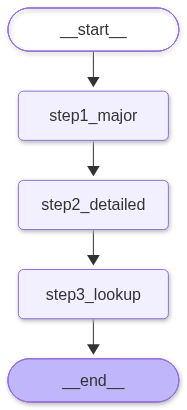

In [15]:
app_2step

### Testing LLM Classfier
- Validated 5% of the dataset (389) randomly selected from 7784 roles (current + target)

In [16]:
unique_roles.shape

(7784, 1)

In [17]:
val_num = int(0.05 * unique_roles.shape[0])
val_num

389

In [18]:
val_roles = unique_roles.sample(val_num)
val_roles

,0
42,Non-IT Worker
8724,Business/Data Analyst
9007,Entry Level Software Engineer
8636,Anything Remote or Legal Assistant/Law Clerk
7334,General Warehouse Associate
...,...
16992,hospitality
7189,3D Asset Designer/Unemployed
7018,System Development Engineer
8118,Project Sales Coordinator


In [25]:
val_sample = val_roles['0'].tolist()[1]

In [26]:
val_sample

'Business/Data Analyst'

In [27]:
app_2step.invoke({"raw_role": val_sample})

{'raw_role': 'Business/Data Analyst',
 'major_code': '13-0000',
 'major_name': 'Business and Financial Operations Occupations',
 'detailed_code': '13-1111',
 'detailed_name': 'Management Analysts',
 'broad_code': '13-1110',
 'minor_code': '13-1000'}